# Intersemestral 2026

Inicialización de librerias:

In [276]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


# Ejercicio 1 — Programación (2 puntos)
a) (0.6 pts) Crea una función rental_fee(duration_min, bike_type, is_member) que calcule la tarifa de un viaje en euros, redondeada a dos decimales, con estas reglas:

In [279]:
def rental_fee(duration_min, bike_type, is_member):
    
    if bike_type == "classic":
        tarifa =1.00 + 0.05*duration_min

    elif bike_type == "electric":
        tarifa = 1.50 +0.08*duration_min

    else:
        raise ValueError("Esta bicicleta no existe")

    if is_member:
        tarifa = tarifa *0.80

    return round(tarifa, 2)  #devolvemos redondeado a dos decimaloes

In [281]:
#comprobar
print(rental_fee(20, "classic", False))
print(rental_fee(20, "classic", True))
print(rental_fee(20, "electric", False))
#print(rental_fee(20, "car", False))

2.0
1.6
3.1


b) (0.6 pts) Crea una función demand_label(total_rentals, threshold) que devuelva "Alta" si total_rentals >= threshold, "Media" si está entre threshold/2 (incluido) y threshold (excluido), y "Baja" en caso contrario.

In [284]:
def demand_label(total_rentals, threshold):

    if total_rentals >=threshold:
        return "Alta"
    elif total_rentals >=threshold/2:
        return "Media"
    else:
        return "Baja"


In [286]:
#comprobar
print(demand_label(50, 40))
print(demand_label(30, 40))
print(demand_label(10, 40))

Alta
Media
Baja


c) (0.6 pts) Genera un DataFrame llamado tripsDemo con al menos 10 filas y columnas:

duration_min (float)
bike_type ("classic" o "electric")
is_member (bool)
fee (calculada con rental_fee)
total_rentals (int, inventado)
demand (calculada con demand_label, usando por ejemplo threshold=40)
Muestra el DataFrame completo.

In [289]:
tripsDemo = pd.DataFrame({
    "duration_min": [10.0, 20.0, 15.5, 30.0, 8.0, 25.0, 12.5, 40.0, 6.0, 18.0],
    "bike_type": ["classic", "classic", "electric", "electric", "classic", "electric", "classic", "electric", "classic", "electric"],
    "is_member": [False, True, False, True, True, False, False, True, True, False],
    "total_rentals": [10, 18, 25, 35, 40, 50, 65, 12, 30, 45] 
    })

#calcular tarifa de cada viaje
tripsDemo["fee"] = tripsDemo.apply(
    lambda fila: rental_fee(
        fila["duration_min"],
        fila["bike_type"],
        fila["is_member"]   ),
    axis=1
    )

#clasificar demanda
tripsDemo["demand"] = tripsDemo["total_rentals"].apply(
    lambda x: demand_label(x, 40)
)


In [291]:
#mostrar todo el DataFrame
display(tripsDemo)

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,10.0,classic,False,10,1.50,Baja
1,20.0,classic,True,18,1.60,Baja
2,15.5,electric,False,25,2.74,Media
3,30.0,electric,True,35,3.12,Media
4,8.0,classic,True,40,1.12,Alta
5,25.0,electric,False,50,3.50,Alta
6,12.5,classic,False,65,1.62,Alta
7,40.0,electric,True,12,3.76,Baja
8,6.0,classic,True,30,1.04,Media
9,18.0,electric,False,45,2.94,Alta


d) (0.2 pts) Integra ambas funciones en una clase MicromobilityTools que, a partir de listas/arrays de duration_min, bike_type e is_member, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de total_rentals y un threshold.

In [294]:
class MicromobilityTools:

    #calcular tarifa
    def calcular_tarifa(self, duracion, tipo, abonado):
        return rental_fee(duracion, tipo, abonado)

    #clasificar demanda
    def clasificar_demanda(self, alquileres, umbral):
        return demand_label(alquileres, umbral)

    #procesar listas
    def procesar(self, duraciones, tipos, abonados,
                alquileres=None, umbral=40):

        datos = pd.DataFrame({
            "duration_min": duraciones,
            "bike_type": tipos,
            "is_member": abonados
        })

        datos["fee"] = datos.apply(
            lambda fila: self.calcular_tarifa(
                fila["duration_min"],
                fila["bike_type"],
                fila["is_member"]
            ),
            axis=1
        )

        if alquileres is not None:
            datos["total_rentals"] = alquileres
            datos["demand"] = datos["total_rentals"].apply(
                lambda x: self.clasificar_demanda(x, umbral)
            )

        return datos

In [296]:
#utilizamos la clase
herramienta = MicromobilityTools()

resultado = herramienta.procesar(
    tripsDemo["duration_min"].tolist(),
    tripsDemo["bike_type"].tolist(),
    tripsDemo["is_member"].tolist(),
    tripsDemo["total_rentals"].tolist(),
    umbral=40
)

In [298]:
#mostrar resultado
display(resultado)

,duration_min,bike_type,is_member,fee,total_rentals,demand
0,10.0,classic,False,1.50,10,Baja
1,20.0,classic,True,1.60,18,Baja
2,15.5,electric,False,2.74,25,Media
3,30.0,electric,True,3.12,35,Media
4,8.0,classic,True,1.12,40,Alta
5,25.0,electric,False,3.50,50,Alta
6,12.5,classic,False,1.62,65,Alta
7,40.0,electric,True,3.76,12,Baja
8,6.0,classic,True,1.04,30,Media
9,18.0,electric,False,2.94,45,Alta


# Ejercicio 2 — Exploración y visualización (3 puntos)
a) (0.75 pts) Carga city_micromobility_hourly.csv en un DataFrame mobilityData. Muestra las 5 primeras filas y el número de filas y columnas.

In [302]:
#cargamos el excel
mobilityData = pd.read_csv("city_micromobility_hourly.csv")

#primeras 5 filas
display(mobilityData.head())

#dimensiones
print("Filas y columnas:", mobilityData.shape)

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


Filas y columnas: (17520, 23)


b) (0.75 pts) Crea una función describeData(dataFrame) que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.

In [305]:
def describeData(dataFrame):

    resultado = pd.DataFrame()
    resultado["Tipo"] = dataFrame.dtypes  #tipo
    resultado["Nulos"] = dataFrame.isna().sum() #nulo
    resultado["% Nulos"] = (
        dataFrame.isna().sum() / len(dataFrame) * 100   #porcentaje del total que son nulos 
    )

    return resultado

In [307]:
#probar la función
display(describeData(mobilityData))

,Tipo,Nulos,% Nulos
datetime,object,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,object,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


c) (0.75 pts) Usa describeData(mobilityData) y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.

In [310]:
descripcion = describeData(mobilityData)

In [312]:
#lo comprobamos
display(descripcion)

,Tipo,Nulos,% Nulos
datetime,object,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,object,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


Las variables con más valores faltantes son avg_trip_min, humidity, electric_share y wind_kmh. 

Aunque los porcentajes de valores faltantes son bajos, lo que yo haría antes de empezar a modelar sería eliminar las filas con nulos para evitar posibles fallos en un futuro cuando procesemos los datos

d) (0.75 pts) Elabora dos visualizaciones:

Un gráfico de correlación entre variables numéricas relevantes (por ejemplo temp_c, humidity, wind_kmh, precip_mm, casual_users, member_users, total_rentals, revenue_eur).
Un gráfico que muestre la demanda media (total_rentals) por hour (y, si quieres, separando fin de semana / laborable).
Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).

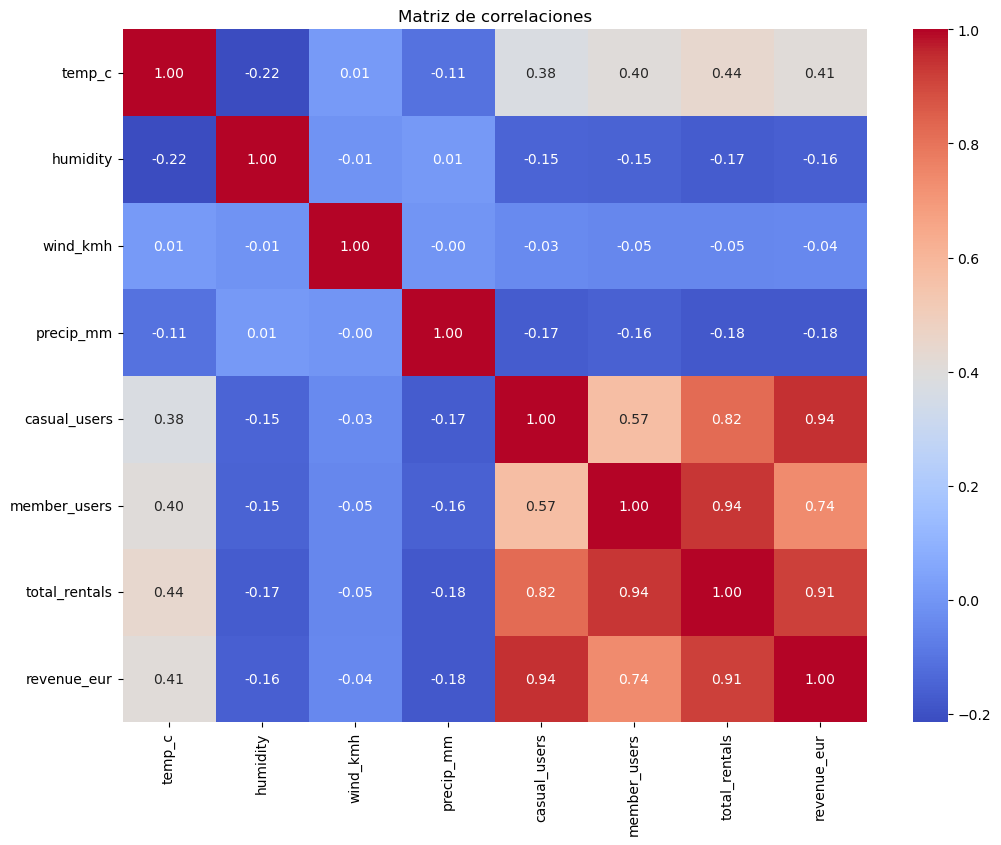

In [316]:
#seleccionar variables numéricas
variables = ["temp_c", "humidity", "wind_kmh", "precip_mm", "casual_users", "member_users", "total_rentals", "revenue_eur"]

#correlaciones
correlaciones = mobilityData[variables].corr()

#matriz
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Matriz de correlaciones")
plt.show()

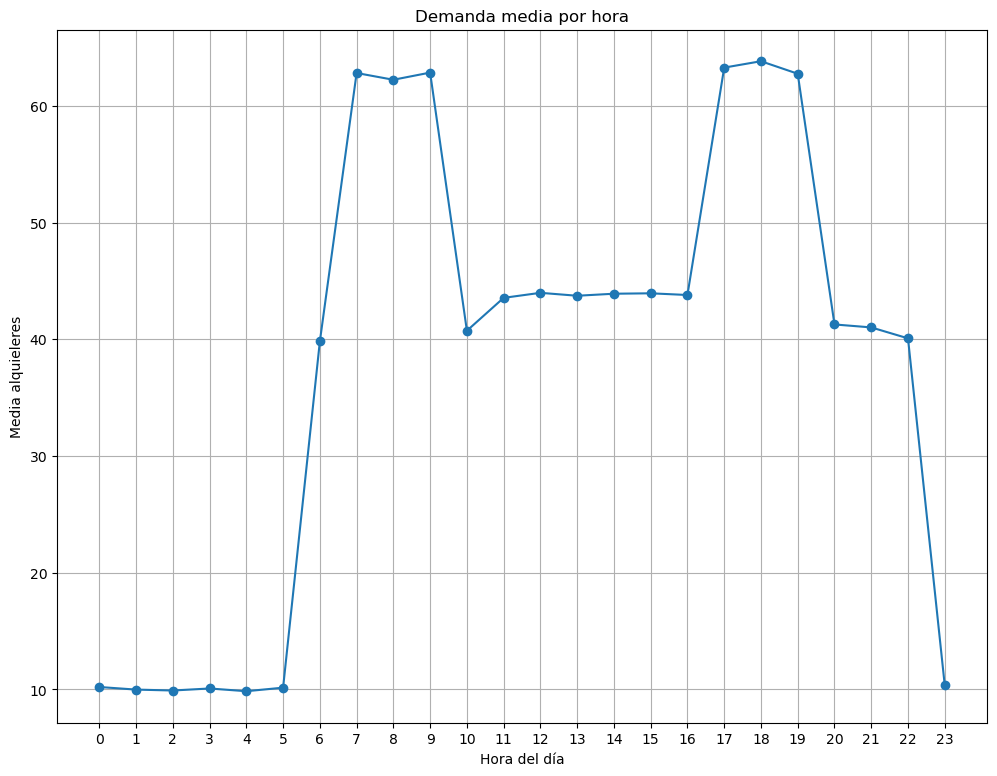

In [318]:
#calcular alquileres medios por hora
demanda_hora = mobilityData.groupby("hour")["total_rentals"].mean()

#dibujar gráfico
plt.figure(figsize=(12, 9))

plt.plot(
    demanda_hora.index,
    demanda_hora.values,
    marker="o"
)

plt.xlabel("Hora del día")
plt.ylabel("Media alquieleres")
plt.title("Demanda media por hora")

plt.xticks(range(24))
plt.grid(True)

plt.show()

La matriz de correlaciones muestra una relación positiva fuerte entre total_rentals y member_users (0,94), revenue_eur (0,91) y casual_users (0,82).
Podiamos esperar estas relaciones porque todas estas variables están directamente vinculadas al volumen total de alquileres.


La temperatura presenta una correlación positiva con la demanda (0,44), mientras que la precipitación (−0,18) y la humedad (−0,17) muestran relaciones negativas más débiles.

En el gráfico de demanda media por hora se observan dos periodos de mayor actividad: de 7:00 a 9:00 y de 17:00 a 19:00. El máximo se alcanza aproximadamente a las 18:00, con 63,82 alquileres de media, posiblemente por desplazamientos laborales.

# Ejercicio 3 — Regresión (2 puntos)
Queremos predecir total_rentals.

a) (0.25 pts) Define targetVar = "total_rentals" y selecciona 3–5 variables predictoras numéricas razonables (p. ej. hour, temp_c, humidity, wind_kmh, precip_mm, is_workingday, is_weekend). Construye X e y, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).

In [323]:
targetVar = "total_rentals"

predictoras = ["hour", "temp_c", "humidity", "precip_mm", "is_workingday"]

#seleccionar columnas y eliminar nulos para evitar errores
datos_modelo = mobilityData[predictoras + [targetVar]].dropna()

#variable predictoras
X = datos_modelo[predictoras]

#variable objetivo
y = datos_modelo[targetVar]

In [325]:
#comprobamos
print(X.head())

   hour  temp_c  humidity  precip_mm  is_workingday
0     0    6.39      67.1        0.0              0
1     1    4.88      37.2        0.0              0
2     2    1.72      79.7        0.0              0
3     3   -3.40      51.4        0.0              0
4     4    8.24      82.2        0.0              0


In [327]:
print(y.head())

0    10
1     6
2     5
3    12
4     5
Name: total_rentals, dtype: int64


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con random_state=42.

In [330]:
#dividimos por prueba y test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,   #30% para test, resto para train
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
#para ver que se cumplen los porcentajes que queriamos (30-70)

Entrenamiento: (12107, 5)
Prueba: (5189, 5)


c) (0.75 pts) Entrena un LinearRegression, calcula R² y MSE en el conjunto de prueba y comenta el resultado en 1–2 líneas.

In [333]:
#crear modelo
modelo_lineal = LinearRegression()

#entrenar y predecir
modelo_lineal.fit(X_train, y_train)
pred_lineal = modelo_lineal.predict(X_test)

#calcular métricas
r2_lineal = r2_score(y_test, pred_lineal)
mse_lineal = mean_squared_error(y_test, pred_lineal)

print("R²:",r2_lineal)
print("MSE:",mse_lineal)

R²: 0.3196213041237773
MSE: 403.6579747805162


El modelo de regresión lineal obtiene un R^2 de 0,3196 y un MSE de 403,6580 en el conjunto de prueba. 

Esto significa que explica aproximadamente el 32% de la variabilidad de los alquileres, una predicción demasiado baja como para un modelo que se pueda considerar bueno

d) (0.75 pts) Entrena un RandomForestRegressor (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?

In [337]:
#crear modelo
modelo_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

#entrenar y predecir
modelo_forest.fit(X_train, y_train)
pred_forest = modelo_forest.predict(X_test)

#métricas
r2_forest = r2_score(y_test, pred_forest)
mse_forest = mean_squared_error(y_test, pred_forest)

# Comparar ambos modelos
print("REGRESIÓN LINEAL")
print("R²:",r2_lineal)
print("MSE:",mse_lineal)

print("RANDOM FOREST")
print("R²:",r2_forest)
print("MSE:",mse_forest)

REGRESIÓN LINEAL
R²: 0.3196213041237773
MSE: 403.6579747805162
RANDOM FOREST
R²: 0.8824481681818322
MSE: 69.74165218731932


El modelo Random Forest funciona claramente mejor que la regresión lineal, ya que consigue un R^2 de 0,882 frente a 0,319 y reduce el MSE de 403,658 a 69,741. Esto indica que explica aproximadamente el 88% de la variabilidad de los alquileres. 

La mejora puede deberse a que Random Forest captura relaciones no lineales entre distintas variables como la demanda, la hora, la temperatura y las condiciones meteorológicas.

# Ejercicio 4 — Clasificación (2 puntos)
Usa la columna high_demand (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (value_counts o proporción) de high_demand.

In [343]:
print("Número de observaciones por clase:")
print(mobilityData["high_demand"].value_counts())

print("\nPorcentaje por clase:")
print(mobilityData["high_demand"].value_counts(normalize=True)* 100)

Número de observaciones por clase:
high_demand
0    12071
1     5449
Name: count, dtype: int64

Porcentaje por clase:
high_demand
0    68.898402
1    31.101598
Name: proportion, dtype: float64


b) (0.75 pts) Entrena un LogisticRegression para predecir high_demand usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar X/y y el split train/test.

In [346]:
#predictores
predictoras_clas = ["hour", "temp_c", "humidity", "precip_mm", "is_workingday"]

#eliminar nulos
datos_clas = mobilityData[
    predictoras_clas + ["high_demand"]
].dropna()  #para quitarlos todos

#X e y
X_clas = datos_clas[predictoras_clas]
y_clas = datos_clas["high_demand"]

#train y test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clas,
    y_clas,
    test_size=0.3,  #test del 30%, resto train.
    random_state=42,
    stratify=y_clas
)

#escalar variables
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

#crear modelo
modelo_logistico = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [348]:
#entrenar
modelo_logistico.fit(X_train_scaled, y_train_c)

LogisticRegression(max_iter=1000, random_state=42)

In [350]:
#predecir
pred_clas = modelo_logistico.predict(X_test_scaled)

In [352]:
print(pred_clas)

[1 0 0 ... 0 0 0]


c) (0.25 pts) Calcula la accuracy y muestra la matriz de confusión.

Accuracy: 0.7574
Accuracy (%): 75.74


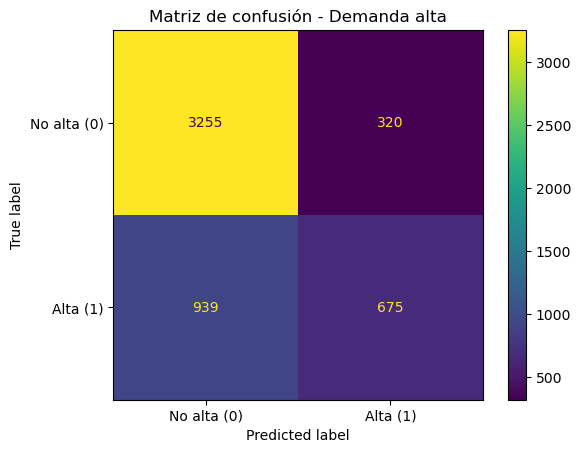

In [355]:
#accuracy
accuracy = accuracy_score(y_test_c, pred_clas)

print("Accuracy:", round(accuracy, 4))
print("Accuracy (%):", round(accuracy *100,2))

#matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test_c,
    pred_clas,
    display_labels=["No alta (0)", "Alta (1)"]
)

plt.title("Matriz de confusión - Demanda alta")
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).

In [358]:
#tabla de coeficientes
coeficientes = pd.DataFrame({
    "Variable": predictoras_clas,
    "Coeficiente": modelo_logistico.coef_[0]
})

#magnitud del coeficiente
coeficientes["Importancia"] = coeficientes["Coeficiente"].abs()

In [360]:
#mostramos
display(coeficientes)

,Variable,Coeficiente,Importancia
0,hour,0.340436,0.340436
1,temp_c,0.763195,0.763195
2,humidity,-0.242819,0.242819
3,precip_mm,-0.807822,0.807822
4,is_workingday,-0.241390,0.241390


La variable más destacada es precip_mm al tener una importancia de 0,8. Mayor que todas las demas. 

# Ejercicio 5 — Conclusión (1 punto)
En un máximo de 300 palabras, resume:

Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.
Qué modelo predictivo te ha funcionado mejor y por qué.
Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


El análisis de los datos de micromovilidad muestra que la demanda de bicicletas y patinetes está relacionada principalmente con la hora del día y las condiciones meteorológicas.

Se observan dos periodos de mayor actividad: entre las 7:00 y las 9:00 y entre las 17:00 y las 19:00, lo cual concuerda con las posibles horas de entrada y salida al trabajo o a la universidad por parte de los usuarios.

Además, la temperatura presenta una correlación positiva con los alquileres (0,44), mientras que la lluvia se relaciona negativamente con la demanda (−0,18). Tiene sentido estos resultados ya que tanto a mejor tiempo la gente usa menos el coche o otros transportes y elige en mayor medida estos como de igual manera en el caso de la lluvia son medios de transporte menos utilizados

En cuanto a los modelos de regresión, Random Forest obtiene los mejores resultados, con un R^2 de 0,882 y un MSE de 69,741, frente al R^2 de 0,319 y MSE de 403,658 de la regresión lineal. Esto puede deberse a su capacidad para captar relaciones no lineales entre las variables.

Para la clasificación de demanda alta, la regresión logística alcanza una accuracy del 75,74%. Los factores más destacados son la precipitación, con una relación negativa, y la temperatura, con una relación positiva. Aunque cabe destacar que el modelo ha mostrado mayor dificultad para predecir en tiempo de demanda alta.

Con más tiempo y tranquilidad para pensar, mejoraría los modelos incorporando información sobre eventos especiales, festivos, otras ciudades y posibles variaciones de precios. También probaría nuevas variables y métodos para mejorar la detección de periodos de alta demanda y mejorar aquellas partes donde el modelo ha tenido mayor dificutad para predecir.